# Signo: recognising 1,000 American Sign Language signs from landmarks

**Students:** John Soni Thomas (CSE-A, Roll No 40, Reg No 240905338), Mokshagna Y (CSE-A, Roll No 42, Reg No 240905354)

This notebook records the research behind Signo's 1,000-sign model. It reads saved results, and does not train anything or read any test clips when it runs. Figures are saved in `figures/`.

In [1]:
import csv, json, os
import pandas as pd
from IPython.display import Image, Markdown, display
R = '../'
load = lambda p: json.load(open(R + p))
audit, raw, base = load('research/audit.json'), load('research/diagnose_raw.json'), load('research/baseline.json')
board = pd.read_csv(R + 'experiments/leaderboard.csv')
choice, rep = load('research/final_choice.json'), load('results/final_test/report.json')
M = rep['models']
show = lambda f: display(Image(filename='figures/' + f))
pc = lambda v: f'{v * 100:.1f}%'
print('Experiments recorded:', len(board), '| Models in the final test:', list(M))

Experiments recorded: 26 | Models in the final test: ['final', 'final_train_only', 'baseline']


## 1. Introduction

Sign recognition lets a computer read signing from an ordinary camera. Signo runs in a web browser: MediaPipe finds the body and hands in each frame, and a neural network names the sign. The task here is **isolated** recognition, one sign per clip, across 1,000 signs, on people the model has never seen.

The question for this work: why does the existing model make the mistakes it does, and what real improvement is possible?

## 2. Research background

| Source | Finding used here |
|---|---|
| Desai et al., ASL Citizen, NeurIPS 2023 | The dataset and its signer-independent protocol. I3D reached 63.10% top-1 and ST-GCN 59.52% on all 2,731 signs. **This is a different vocabulary, so these numbers are not comparable with ours** |
| Vandendriessche et al., 2025, one-shot ISLR | A pose-based PoseFormer reached Rec@1 of about 0.75 on ASL Citizen. Its ablation credits a frame embedding with +0.0278 |
| Hoyeol Sohn, Kaggle ISLR 1st place | 1D convolutions with attention, on lips, hands, nose and eyes, with motion channels |
| Kaggle ISLR 2nd place write-up | Motion, distances, heavy augmentation including mixup, 100 to 210 epochs |
| dos Santos et al., 2025, LIBRAS | A chosen landmark subset beat using all points, and filling gaps helped |
| Bai et al., 2018 | Simple temporal convolutions match or beat recurrent networks on many tasks |

Full notes, including sources that could not be read, are in `research/LITERATURE_REVIEW.md`.

## 3. Dataset

ASL Citizen is Microsoft's crowdsourced dataset, used under its research licence. No clips or landmarks are included here.

,Split,Clips,Signers,Clips per sign (min),Clips per sign (median),Clips per sign (max)
0,train,14626,35,11,15.0,17
1,val,3763,5,2,4.0,6
2,test,3983,11,3,4.0,4


Signer overlap between splits: {'train-val': [], 'train-test': [], 'val-test': []}
Duplicate video IDs: 0 | Non-finite values: 0 | Clips dropped for too few hand frames: 49


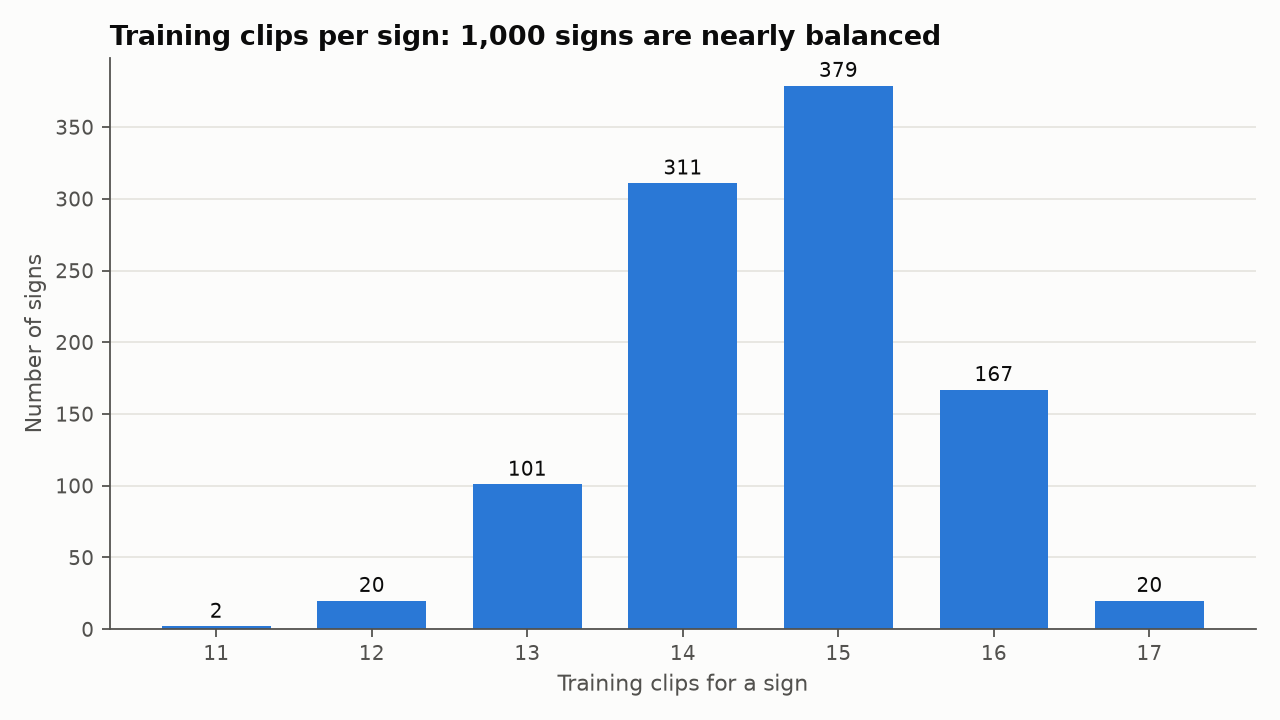

In [2]:
display(pd.DataFrame([{'Split': s, 'Clips': audit['clips'][s], 'Signers': len(audit['signers'][s]), 'Clips per sign (min)': audit['per_class'][s]['min'], 'Clips per sign (median)': audit['per_class'][s]['median'], 'Clips per sign (max)': audit['per_class'][s]['max']} for s in ('train', 'val', 'test')]))
print('Signer overlap between splits:', audit['signer_overlap'])
print('Duplicate video IDs:', audit['duplicate_video_ids'], '| Non-finite values:', audit['non_finite_values'], '| Clips dropped for too few hand frames:', audit['dropped_no_hands']['total'])
show('class_distribution.png')

## 4. Preprocessing

Each clip is trimmed to the span where a hand is visible, with 2 frames either side, then sampled to 30 frames using the nearest frame. Coordinates are centred on the midpoint of the shoulders and divided by shoulder width. Rebuilding features from saved raw landmarks matched the stored values to within 0.0007 on 400 of 400 clips, which checks the pipeline.

Sampling keeps most movement: the median hand span is 38 frames, and 30 frames keep about 95% of fingertip movement at the median.

## 5. Feature extraction

Each frame gives 100 numbers: 7 body points (14), left hand (42), right hand (42) and 2 flags for whether each hand is present. Missing hands are zeros. MediaPipe Holistic uses the same settings in Python and in the browser.

This research tested other features, built separately. None replaced the 30 x 100 input.

## 6. Baseline architecture

The baseline, `final_v2`, averages two bidirectional LSTMs of 128 units, each followed by a dense layer. It takes 114 ms per prediction in the browser.

In [3]:
display(pd.DataFrame([{'Measure': k.replace('_', ' '), 'Baseline, validation': pc(base[k])} for k in ('top1', 'top5', 'macro_precision', 'macro_recall', 'macro_f1')]))
print('Re-running the saved baseline on validation matched its saved predictions to within 1e-14.')

,Measure,"Baseline, validation"
0,top1,79.4%
1,top5,95.0%
2,macro precision,82.3%
3,macro recall,79.9%
4,macro f1,78.9%


Re-running the saved baseline on validation matched its saved predictions to within 1e-14.


## 7. Experimental methodology

- **Splits:** the official signer-independent splits. No signer appears in two splits.
- **Selection:** validation only. Test clips are removed before a training process starts.
- **Automation:** `python/auto_optimize.py` trains from a queue, scores each run, compares it, queues follow-ups and keeps `experiments/BEST_MODEL.json`.
- **Comparisons:** a paired bootstrap on shared validation clips gives a 95% interval, so small differences are not called gains.
- **Quick tests:** ideas were first compared on 5,000 training clips. Those scores are only meaningful against each other.
- **Test:** `python/final_eval.py` runs once and refuses to run again. It also uses 8,161 official test clips never used before, because the earlier 3,983 had already been scored twice.

The diagnosis in `research/DIAGNOSIS.md` found the main limit is data: a large gap between training and validation accuracy, and accuracy that rises sharply with the number of clips.

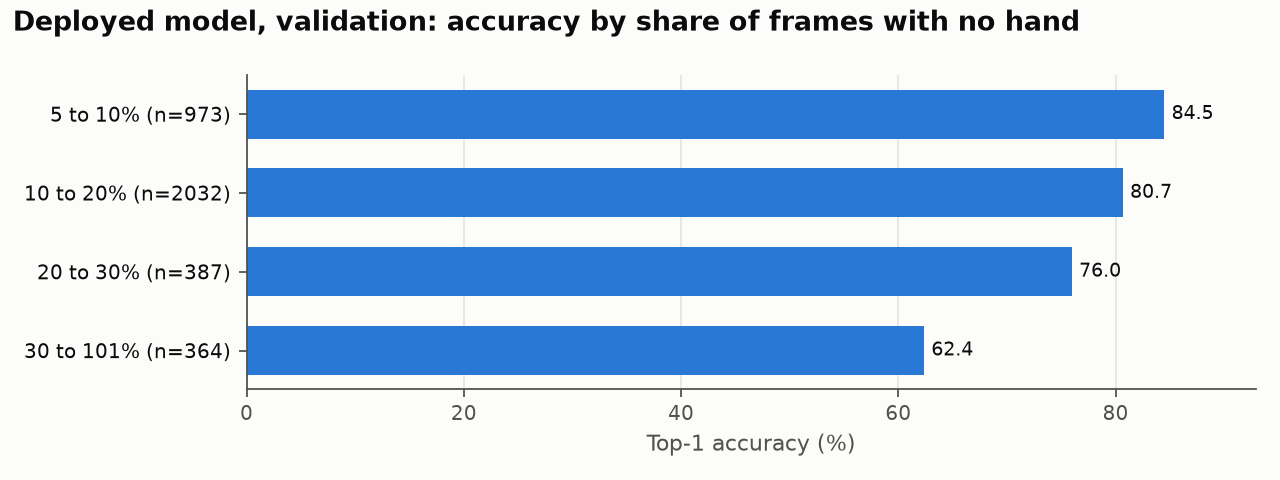

Top-1 falls as more of a clip has no visible hand. This is a correlation, so it was tested directly in section 8.

In [4]:
show('accuracy_by_tracking_gaps.png')
display(Markdown('Top-1 falls as more of a clip has no visible hand. This is a correlation, so it was tested directly in section 8.'))

## 8. Research-driven improvements

The quick tests on 5,000 training clips came first, against a control.

,name,top1,top5,macro_f1,gap
12,gate_body_mix,0.6088,0.8496,0.5850,0.3815
13,gate_mixup,0.5995,0.8366,0.5763,0.3945
14,gate_smooth,0.5748,0.8371,0.5506,0.4145
15,gate_velocity,0.5676,0.8119,0.5457,0.4287
16,gate_interp,0.5623,0.8089,0.5394,0.4337
17,gate_body_aug,0.5581,0.8150,0.5360,0.4309
18,gate_linear,0.5562,0.8119,0.5340,0.4408
19,gate_base,0.5551,0.8089,0.5351,0.4402
20,gate_t45,0.5286,0.7909,0.5052,0.4651
21,gate_face,0.4874,0.7627,0.4624,0.4830


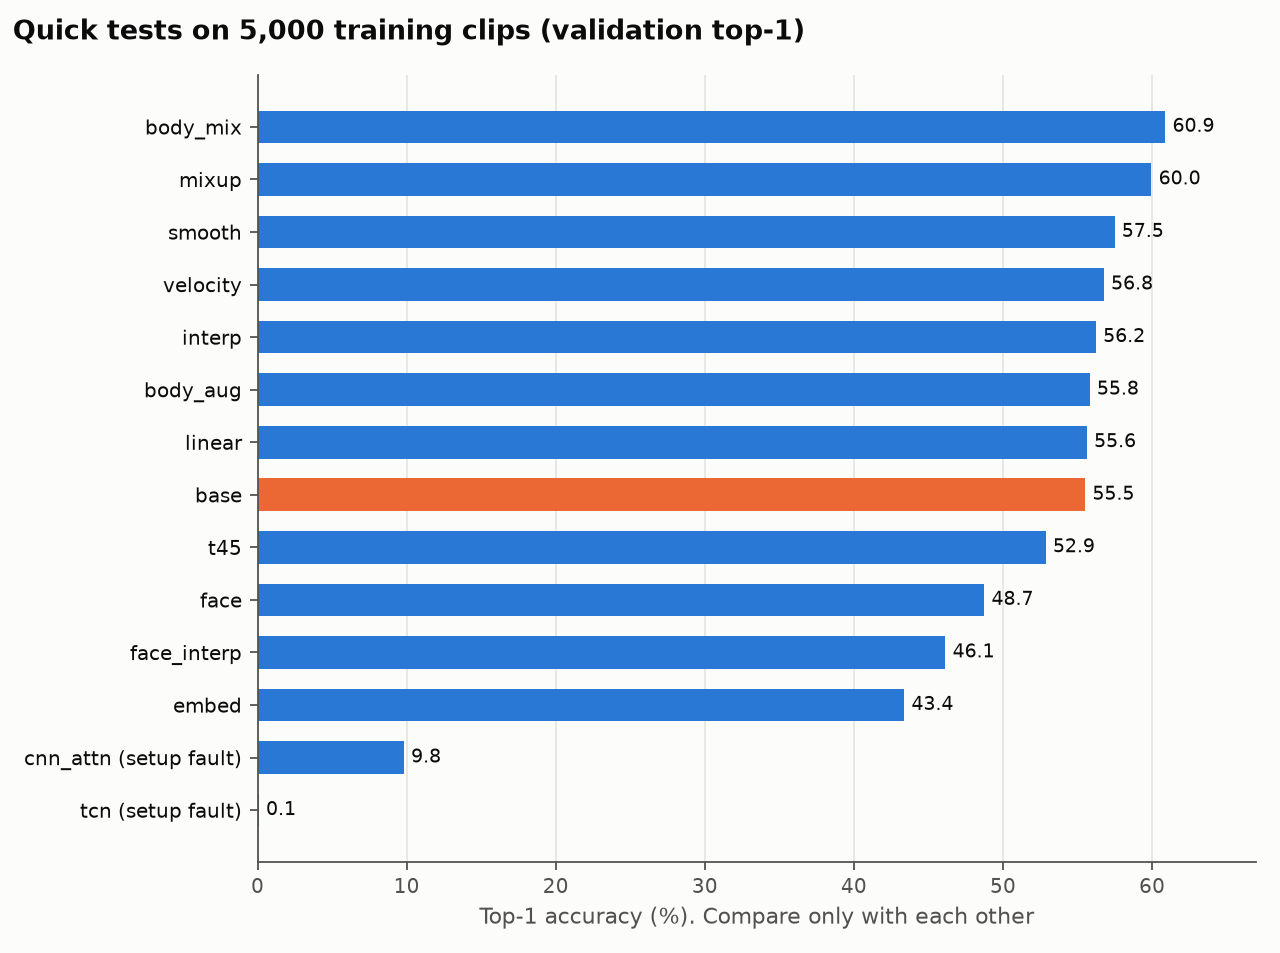

In [5]:
g = board[board.partial_train.notna()].sort_values('top1', ascending=False)[['name', 'top1', 'top5', 'macro_f1', 'gap']].copy()
display(g.round(4))
show('gate_comparison.png')

Promising ideas then ran on all 14,626 training clips. These are compared with the baseline on the same validation clips.

,id,name,arch,top1,top5,macro_f1,gap,best_epoch,params,train_minutes
0,exp_022,full_tcn_fair,tcn,0.8432,0.9663,0.8394,0.1565,148,1322344,141.0
1,exp_028,tcn_always_s1,tcn,0.8384,0.9689,0.8341,0.1579,119,1322344,108.6
2,exp_029,tcn_always_s2,tcn,0.8360,0.9686,0.8309,0.1616,126,1322344,107.2
3,exp_025,full_mixup_always+moretime,bilstm,0.8315,0.9692,0.8249,0.1311,200,396392,89.2
4,exp_017,full_mixup_always,bilstm,0.8212,0.9652,0.8144,0.1242,179,396392,127.1
5,exp_024,full_mixup_always+seed1,bilstm,0.8204,0.9678,0.8152,0.1260,171,396392,66.0
6,exp_019,full_mixup_u192,bilstm,0.8134,0.9631,0.8056,0.1776,174,716968,162.1
7,exp_026,always_velocity,bilstm,0.8126,0.9644,0.8063,0.1314,148,518792,92.9
8,exp_027,full_mixup_always+smooth,bilstm,0.8119,0.9647,0.8059,0.1155,150,396392,81.9
9,exp_016,full_mixup_smooth,bilstm,0.8079,0.9596,0.8036,0.1411,153,396392,128.3


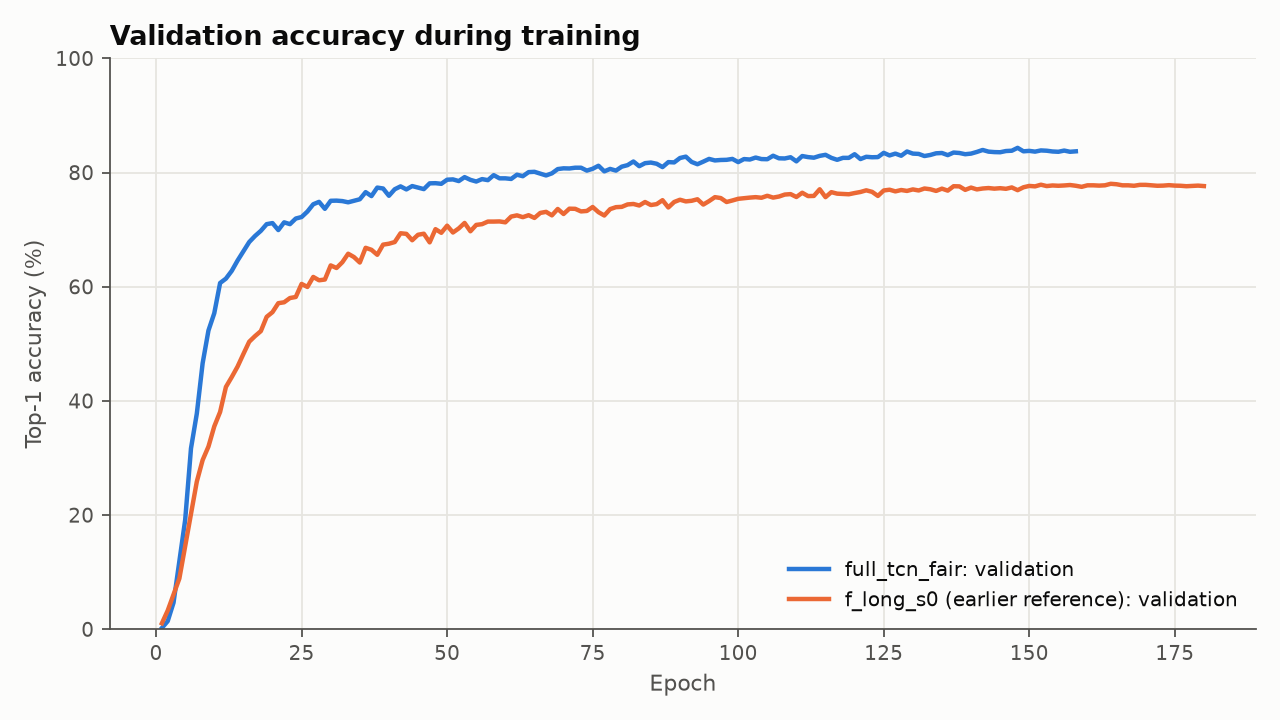

In [6]:
f = board[board.partial_train.isna()].sort_values('top1', ascending=False)[['id', 'name', 'arch', 'top1', 'top5', 'macro_f1', 'gap', 'best_epoch', 'params', 'train_minutes']].copy()
display(f.round(4))
show('training_curves.png')

## 9. Model comparison

The final model was chosen on validation by a rule fixed in advance: grow an ensemble greedily, stop when a member adds under 0.3 points, at most 4 members.

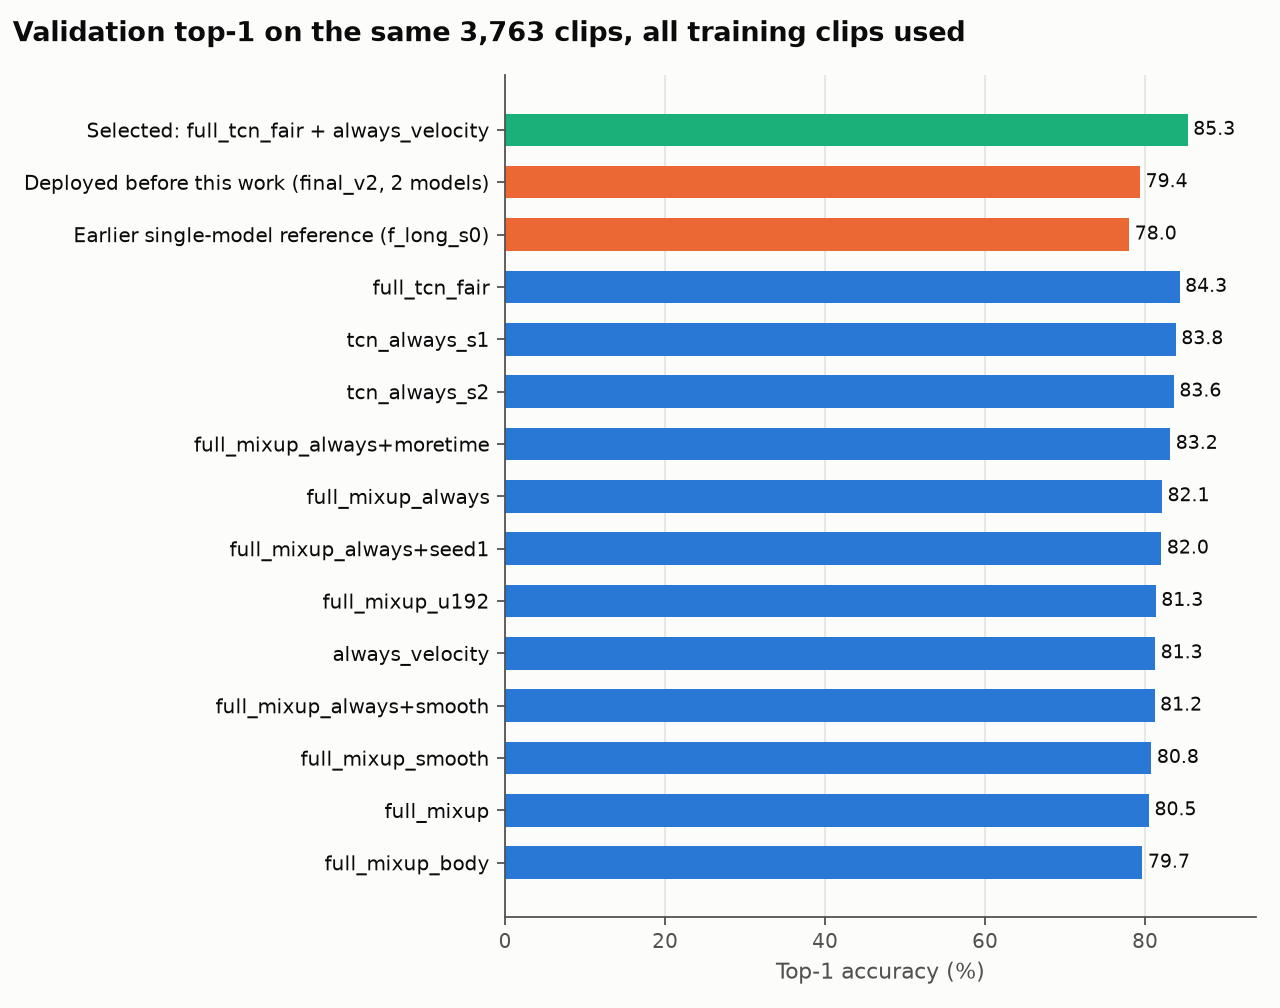

,added,top1,tried,stopped
0,exp_022,0.8432,NaN,NaN
1,exp_026,0.8533,NaN,NaN
2,NaN,0.8562,exp_017,gain +0.0029 is below 0.003


,Member,Name,Own validation top-1,Temperature
0,exp_022,full_tcn_fair,84.3%,0.90
1,exp_026,always_velocity,81.3%,0.84


Ensemble on validation: {'top1': 0.8533, 'top5': 0.9732, 'macro_precision': 0.8723, 'macro_recall': 0.857, 'macro_f1': 0.8487, 'ece': 0.0517, 'shown_at_0_7': 0.7101, 'correct_when_shown_at_0_7': 0.9689}


In [7]:
show('model_comparison.png')
display(pd.DataFrame(choice['trace']).round(4))
display(pd.DataFrame([{'Member': m['id'], 'Name': m['name'], 'Own validation top-1': pc(m['solo_top1']), 'Temperature': round(m['temperature'], 2)} for m in choice['members']]))
print('Ensemble on validation:', {k: round(v, 4) for k, v in choice['val'].items()})

Why this model: it scored highest on validation under that rule, it needs no change to the 30 x 100 input, and it is faster in the browser than the baseline. The deployed copy was retrained on training plus validation clips, as planned before any test score existed.

## 10. Final test results

In [8]:
rows = []
for s, name in (('fresh', 'Unseen test clips'), ('used', 'Earlier test clips (scored before)')):
    for m, label in (('final', 'Final'), ('final_train_only', 'Training clips only'), ('baseline', 'Baseline final_v2')):
        r = M[m][s]
        rows.append({'Test set': name, 'Clips': r['n'], 'Model': label, 'Top-1': pc(r['top1']), '95% interval': f"{pc(r['top1_ci95'][0])} to {pc(r['top1_ci95'][1])}", 'Top-5': pc(r['top5']), 'Macro precision': pc(r['macro_precision']), 'Macro recall': pc(r['macro_recall']), 'Macro F1': pc(r['macro_f1']), 'Weighted F1': pc(r['weighted_f1'])})
display(pd.DataFrame(rows))
print(json.dumps(rep['paired_vs_baseline'], indent=1))

,Test set,Clips,Model,Top-1,95% interval,Top-5,Macro precision,Macro recall,Macro F1,Weighted F1
0,Unseen test clips,8134,Final,83.2%,82.4% to 84.0%,96.4%,84.4%,83.2%,82.8%,82.9%
1,Unseen test clips,8134,Training clips only,81.1%,80.2% to 82.0%,95.6%,82.2%,81.0%,80.6%,80.8%
2,Unseen test clips,8134,Baseline final_v2,74.1%,73.2% to 75.1%,92.6%,75.4%,74.2%,73.6%,73.7%
3,Earlier test clips (scored before),3983,Final,83.8%,82.7% to 84.9%,96.6%,85.2%,83.8%,83.1%,83.1%
4,Earlier test clips (scored before),3983,Training clips only,81.8%,80.5% to 83.0%,95.6%,84.1%,81.8%,81.3%,81.3%
5,Earlier test clips (scored before),3983,Baseline final_v2,73.4%,72.0% to 74.7%,92.0%,75.4%,73.4%,72.5%,72.5%


{
 "final/used": {
  "diff": 0.10394175244790359,
  "ci95": [
   0.09189053477278433,
   0.11624403715792117
  ]
 },
 "final/fresh": {
  "diff": 0.09073026801081878,
  "ci95": [
   0.08200147528891075,
   0.09872141627735431
  ]
 },
 "final_train_only/used": {
  "diff": 0.08410745669093649,
  "ci95": [
   0.0725520964097414,
   0.09615867436605574
  ]
 },
 "final_train_only/fresh": {
  "diff": 0.06958446029014015,
  "ci95": [
   0.061836119990164744,
   0.07769854929923777
  ]
 }
}


## 11. Confusion matrix

A 1,000 x 1,000 matrix cannot be read on a page, so this shows the 30 lowest-recall signs. The full matrix is in `results/final_test/`.

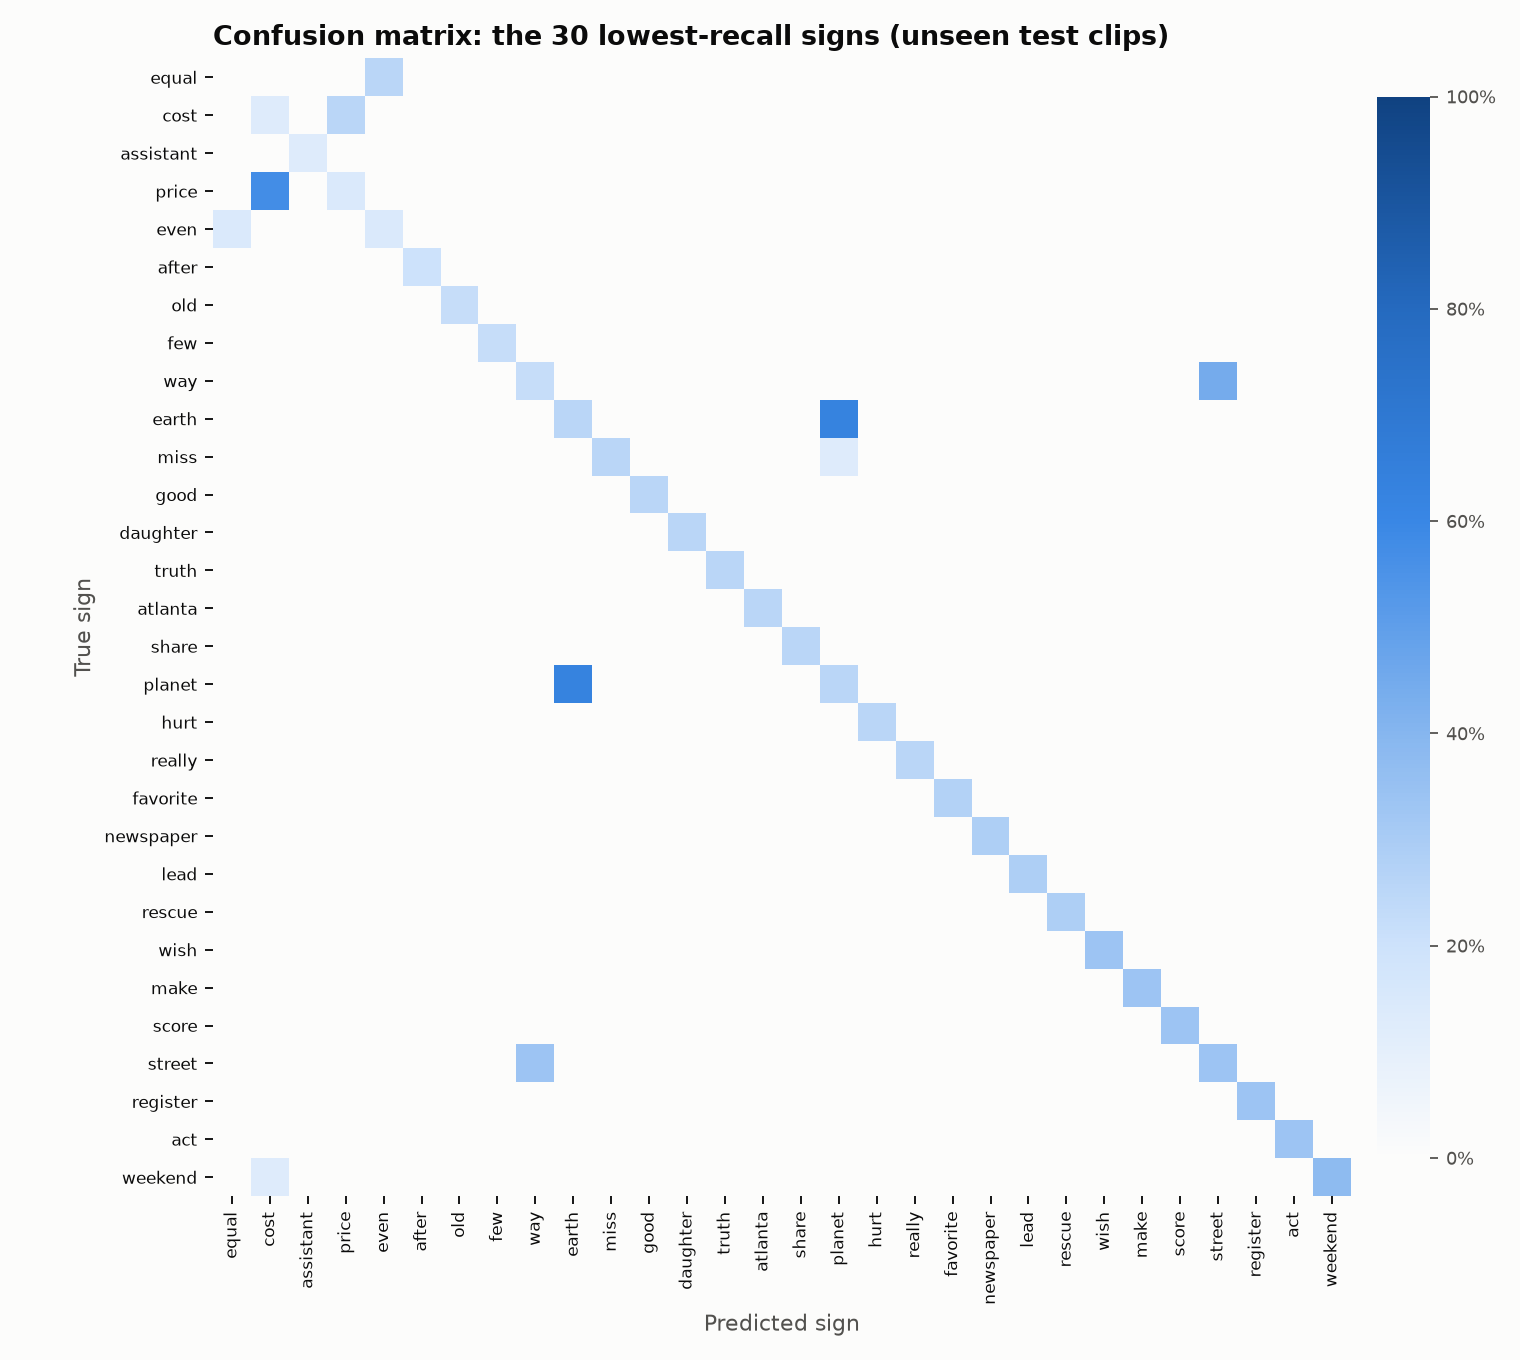

In [9]:
show('confusion_matrix.png')

## 12. Error analysis

,best_sign,best_test_clips,best_precision,best_recall,best_f1,worst_sign,worst_test_clips,worst_precision,worst_recall,worst_f1
0,above,8,1.0,1.0,1.0,equal,8,0.0000,0.0000,0.0000
1,important,11,1.0,1.0,1.0,cost,8,0.1429,0.1250,0.1333
2,impact,7,1.0,1.0,1.0,assistant,8,0.2500,0.1250,0.1667
3,idea,7,1.0,1.0,1.0,even,7,0.2000,0.1429,0.1667
4,ice,8,1.0,1.0,1.0,price,7,0.3333,0.1429,0.2000
5,hundred,8,1.0,1.0,1.0,earth,8,0.2500,0.2500,0.2500
6,high,9,1.0,1.0,1.0,planet,8,0.2500,0.2500,0.2500
7,improve,8,1.0,1.0,1.0,way,9,0.2857,0.2222,0.2500
8,health,10,1.0,1.0,1.0,few,9,0.4000,0.2222,0.2857
9,hate,7,1.0,1.0,1.0,rescue,7,0.2857,0.2857,0.2857


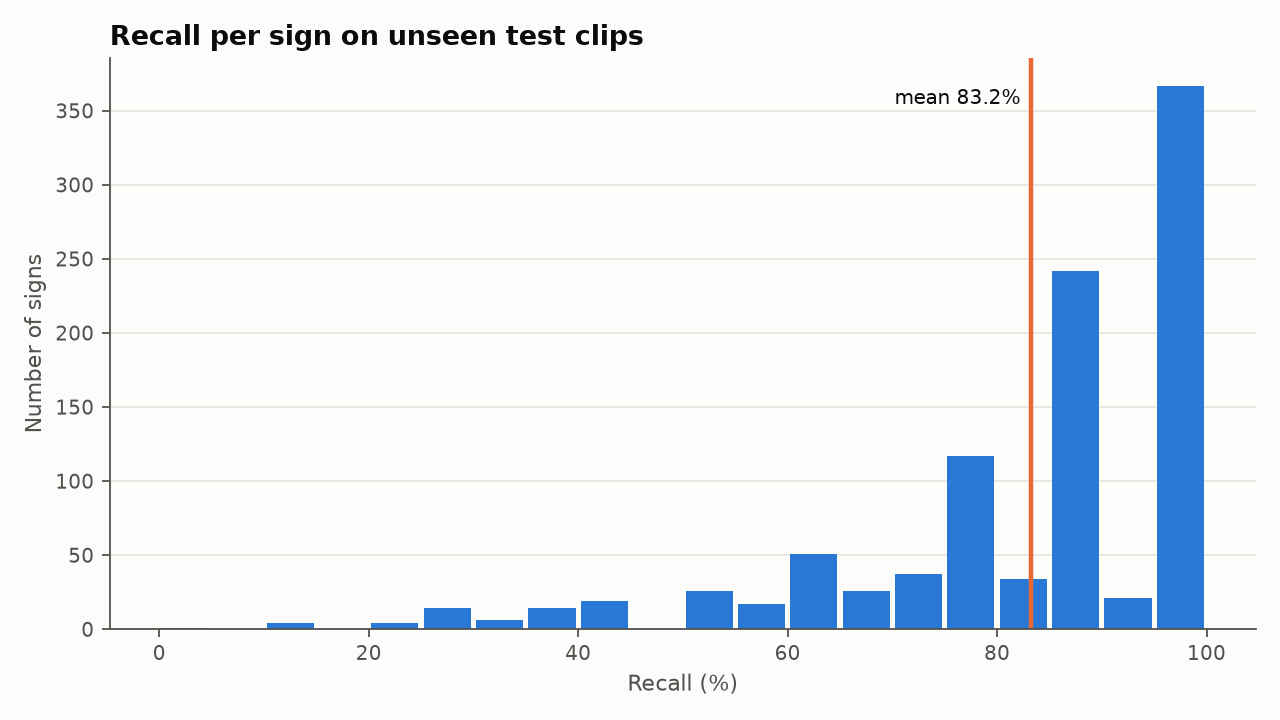

Across the 11 test signers, top-1 ranges from 76.6% to 92.0%.


In [10]:
pcs = pd.read_csv(R + 'results/final_test/final_fresh_per_class.csv')
display(pd.concat([pcs.head(10).reset_index(drop=True).add_prefix('best_'), pcs.tail(10).iloc[::-1].reset_index(drop=True).add_prefix('worst_')], axis=1))
show('per_class_performance.png')
sig = M['final']['fresh']['by_signer']
vals = sorted(sig.values())
print(f'Across the {len(vals)} test signers, top-1 ranges from {pc(vals[0])} to {pc(vals[-1])}.')

## 13. Discussion

In [11]:
display(Markdown(open(R + 'research/final_discussion.md').read()))

## Discussion

**What improved.** On never-used test clips, top-1 rose from 74.1% to 83.2%, top-5 from 92.6% to 96.4% and macro F1 from 73.6% to 82.8%. On the same clips the gain is 9.1 points (95% interval 8.2 to 9.9). Signs with recall of 50% or less fell from 171 to 88. All 11 test signers improved, and the lowest signer rose from 66.7% to 76.6%. The model is also faster in the browser, at 68 ms against 116 ms.

**Which experiment gave the largest gain.** The temporal convolution network, at 84.32% on validation, 6.3 points above the earlier single BiLSTM (95% interval 5.1 to 7.5). Blending clips in every batch (mixup) was next, adding 4.1 points to the same BiLSTM (interval 3.0 to 5.3). Combining two models added 1.0 point on validation.

**Whether another architecture beat the BiLSTM.** Yes, narrowly at equal effort. The TCN beat the best BiLSTM, which ran 240 epochs, by 1.2 points (interval 0.05 to 2.3). The earlier conclusion that convolution does not work here came from a setup fault and runs cut short, not from the architecture. The chosen pair is one TCN and one BiLSTM.

**Whether more data helped.** No new clips exist for these signs. Adding the 3,763 validation clips to the final training, as planned in advance, added 2.1 points on the unseen clips (interval 1.5 to 2.7), which supports data being the main limit. Pretraining on the other 1,731 signs was not tried.

**Whether augmentation helped.** Mixup did. Hand-size and arm-length variation did not: on all clips it scored 79.67% against 80.49% without it. Earlier work had already shown that mirroring and time warping help.

**What did not help (5,000-clip tests against 55.51%, unless stated).**

| Idea | Result | 95% interval |
|---|---:|---:|
| Face points | -6.8 points | -8.2 to -5.3 |
| Face points and bridged hand gaps | -9.4 | -10.9 to -7.9 |
| Frame embedding | -12.1 | -13.7 to -10.6 |
| 45 frames | -2.7 | -4.1 to -1.2 |
| Bridging hand gaps | +0.7 | -0.6 to +2.1 |
| Blended frame sampling | +0.1 | -1.3 to +1.4 |
| Motion input, on all clips and with mixup | -0.9 against the same run without it | -1.9 to +0.2 |
| Label smoothing with mixup, on all clips | 81.19% against 82.12% | |

The face result is the most surprising, since top Kaggle solutions use face points. One possible cause is that face shape lets the model recognise the signer, as the gap widened, but this was not tested. The frame embedding result also disagrees with a published ablation, and it was tested only on 5,000 clips with a BiLSTM, so it is not a general verdict. The BiLSTM with motion input was chosen as the second ensemble member because it added the most when combined, not because motion input helps.

**Whether the model is still overfitting.** Yes. The TCN scores 99.97% on clean training clips against 84.32% on validation, a gap of 15.7 points. Earlier members had a gap of about 18 points, so this has improved only somewhat.

**Whether signer-independent generalisation improved.** Yes, for every test signer, but signers still range from 76.6% to 92.0%. The 16:9 signer's score rose from 78.6% to 87.6%. Correcting for video shape probably contributes, but the model also changed, so the two effects were not separated.

**Validation against test.** The training-only ensemble scored 85.33% on validation and 81.09% on the unseen test clips. Part of that 4.2-point drop is likely from many comparisons on the same validation clips, and part from different signers.

**What remains the main bottleneck.** Too few clips per sign and too few signers, shown by the training gap and by the rise from adding validation clips. The next limit is similar signs: top-5 is 13.2 points above top-1, and the top 100 confused pairs hold 34% of errors, including earth and planet, assist and assistant, experience and experienced, register and rule. Some of these may be very close or the same sign. Real webcam accuracy has still not been measured.

**About the test sets.** The 3,983 earlier clips have now been scored in version 1, version 2 and here, so they are not untouched. The 8,134 clips were first scored in this one run, after all choices were fixed, so that is the score to quote. Both sets come from the same 11 test signers.


## 14. Limitations

- **No real webcam measurement.** All scores come from dataset video. Real webcam accuracy has not been measured.
- **Same test signers.** Both test sets come from the same 11 official test signers, so the score may not hold for very different signers or cameras.
- **Few clips per sign in testing.** Per-sign scores carry large uncertainty.
- **Validation was used heavily.** Many runs were compared on the same 3,763 clips, so validation scores are somewhat optimistic. The test score is the one to trust.
- **Not all planned work was done.** Pretraining on the other 1,731 signs was not tested, and graph networks had no fair test (one attempt reached 3 epochs on a time budget). Both remain future work.
- **Some signs may be near-duplicates,** such as star and stars, which limits any model on this vocabulary.

## 15. Conclusion

The main limit was data per sign. The largest gains came from training methods and from giving a different architecture a fair test, not from more input features. See section 10 for the final scores.

## 16. References

1. Desai et al. ASL Citizen: A Community-Sourced Dataset for Advancing Isolated Sign Language Recognition. NeurIPS 2023. https://arxiv.org/abs/2304.05934
2. Microsoft. ASL Citizen code. https://github.com/microsoft/ASL-citizen-code
3. Vandendriessche et al. Representing Signs as Signs: One-Shot ISLR. 2025. https://arxiv.org/abs/2502.20171
4. Hoyeol Sohn. Google Isolated Sign Language Recognition, 1st place solution. https://github.com/hoyso48/Google---Isolated-Sign-Language-Recognition-1st-place-solution
5. Kaggle ISLR 2nd place write-up. https://habr.com/en/articles/795109
6. dos Santos et al. Proper Body Landmark Subset for LIBRAS. 2025. https://arxiv.org/html/2510.24887v3
7. Kvanchiani et al. Training Strategies for Isolated Sign Language Recognition. 2024. https://arxiv.org/html/2412.11553v1
8. Bai, Kolter, Koltun. An Empirical Evaluation of Generic Convolutional and Recurrent Networks. 2018. https://arxiv.org/abs/1803.01271
9. Zhang et al. mixup: Beyond Empirical Risk Minimization. ICLR 2018. https://arxiv.org/abs/1710.09412
10. Guo et al. On Calibration of Modern Neural Networks. ICML 2017. https://arxiv.org/abs/1706.04599